#           __NOTE__
# __I had a problem on Kaggle so i had to write it on VS Code__


## ---------------------------------------------------------------------------------

# __Part 1: Import Required Libraries__

In [56]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os

import kagglehub


import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# __Part 2: Define Dataset Paths__

In [4]:
dataset_path = kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")
print(dataset_path)
print(os.listdir(dataset_path))

100%|██████████| 534M/534M [02:42<00:00, 3.45MB/s] 

Extracting files...


C:\Users\moham\.cache\kagglehub\datasets\misrakahmed\vegetable-image-dataset\versions\1
['Vegetable Images']


In [9]:
base_dir = os.path.join(dataset_path, "Vegetable Images")

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
validation_dir = os.path.join(base_dir, "validation")

print(os.path.exists(train_dir), os.path.exists(test_dir), os.path.exists(validation_dir))

True True True


In [10]:
os.listdir(train_dir)

['Bean',
 'Bitter_Gourd',
 'Bottle_Gourd',
 'Brinjal',
 'Broccoli',
 'Cabbage',
 'Capsicum',
 'Carrot',
 'Cauliflower',
 'Cucumber',
 'Papaya',
 'Potato',
 'Pumpkin',
 'Radish',
 'Tomato']

# __Part 3: Count Images in Each Class__

In [31]:
def count_img(path):
    counts={}
    for class_name in os.listdir(path):
        counts[class_name]=len(os.listdir(path+'/'+ class_name))
    return counts

In [33]:
train_counts = count_img(train_dir)
test_counts = count_img(test_dir)
val_counts = count_img(validation_dir)

In [34]:
train_counts

{'Bean': 1000,
 'Bitter_Gourd': 1000,
 'Bottle_Gourd': 1000,
 'Brinjal': 1000,
 'Broccoli': 1000,
 'Cabbage': 1000,
 'Capsicum': 1000,
 'Carrot': 1000,
 'Cauliflower': 1000,
 'Cucumber': 1000,
 'Papaya': 1000,
 'Potato': 1000,
 'Pumpkin': 1000,
 'Radish': 1000,
 'Tomato': 1000}

In [35]:
test_counts

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

In [36]:
val_counts

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

# __Part 4: Create a Summary DataFrame__

In [37]:
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


# __Part 5: Visualize Class Distribution__

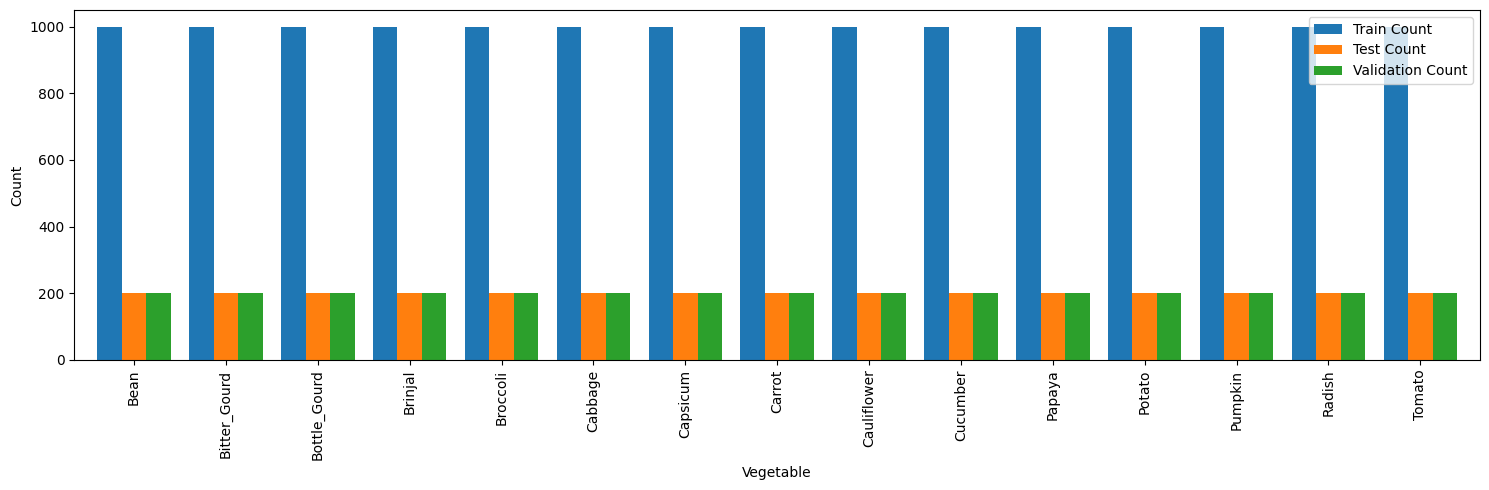

In [53]:
summary_df.set_index("Vegetable").plot(kind="bar", figsize=(15, 5), width=0.8)


plt.xlabel("Vegetable")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

## __Yes the data set is balanced because each class has the same number of images__


# ---------------------------------------------------------------------

# __Part 6: Image Preprocessing and Augmentation__

In [54]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# __Part 7: Load Images Using flow_from_directory__

In [55]:
train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
     seed=42,
    subset="training"
   
)

val_ds = val_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    seed=42,
    subset="validation"
    
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


# __Part 8: Build the CNN Model__

In [60]:
model = Sequential()

model.add(Conv2D(filters=32, kernel_size=3, activation="relu", input_shape=(224, 224, 3)))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(filters=64, kernel_size=3, activation="relu"))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(filters=128,kernel_size=3, activation="relu"))
model.add(MaxPooling2D((2, 2)))


model.add(Flatten())

model.add(Dense(512, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(15, activation="softmax"))


c:\Users\moham\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# __Part 9: Compile the Model__

In [61]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)



In [62]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

# -----------------------------------------------------------------
### __Number of convolutional layers:__ _3_
### __Purpose of pooling layers:__ _To shrink the feature map_
### __Why softmax is used in the output layer:__ _To converts the output into probabilities_
# -----------------------------------------------------------------

# __Part 10: Train the Model__

In [64]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 352s 937ms/step - accuracy: 0.5934 - loss: 1.2014 - val_accuracy: 0.7610 - val_loss: 0.6967
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 232s 619ms/step - accuracy: 0.7007 - loss: 0.9055 - val_accuracy: 0.7330 - val_loss: 0.7880
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 230s 612ms/step - accuracy: 0.7520 - loss: 0.7597 - val_accuracy: 0.8413 - val_loss: 0.4602
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 231s 615ms/step - accuracy: 0.7838 - loss: 0.6608 - val_accuracy: 0.9017 - val_loss: 0.3096
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 231s 616ms/step - accuracy: 0.8081 - loss: 0.5969 - val_accuracy: 0.8900 - val_loss: 0.3488
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 231s 616ms/step - accuracy: 0.8234 - loss: 0.5451 - val_accuracy: 0.8710 - val_loss: 0.4241
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 232s 619ms/step - accuracy: 0.8471 - loss: 0.4787 - val_accuracy: 0.9217 - val_loss: 0.2425
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 232s 617ms/step - accuracy: 0.8562 -

# __Part 11: Evaluate the Model__

In [65]:
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)

print(f"Training Accuracy  : {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Training Loss      : {train_loss:.4f}")
print(f"Validation Loss    : {val_loss:.4f}")

375/375 ━━━━━━━━━━━━━━━━━━━━ 115s 307ms/step - accuracy: 0.9087 - loss: 0.2887
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 118ms/step - accuracy: 0.9430 - loss: 0.1798
Training Accuracy  : 0.9087
Validation Accuracy: 0.9430
Training Loss      : 0.2887
Validation Loss    : 0.1798


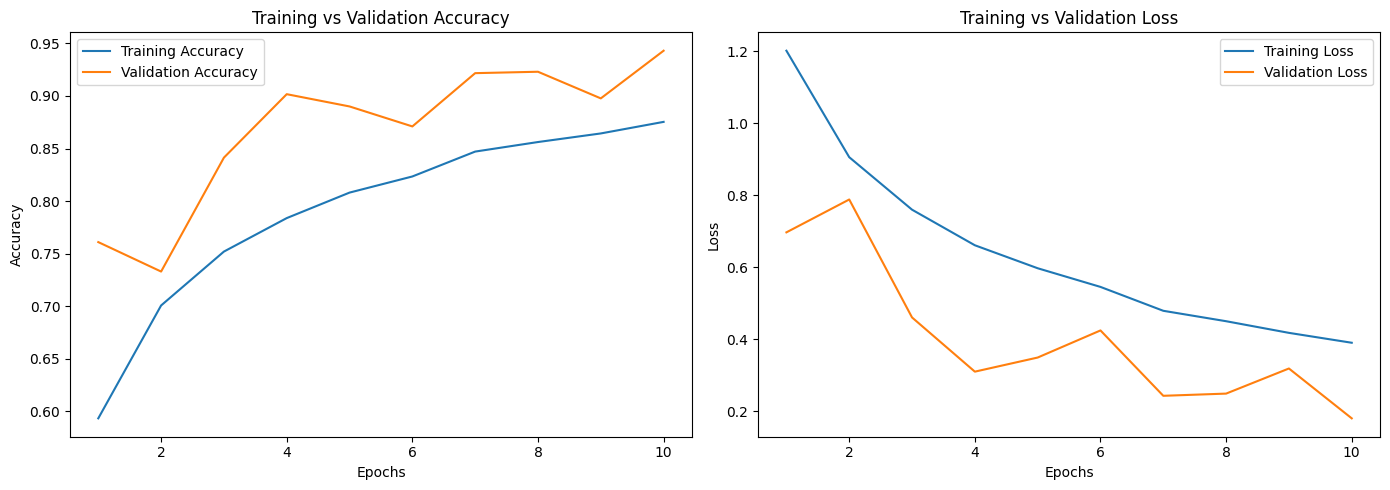

In [66]:
acc = history.history["accuracy"]
val_acc_hist = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss_hist = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc_hist, label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss_hist, label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()